In [33]:
import pandas as pd
import numpy as np
import seaborn as sns

# Quiz Questions

Use this dataset to do the following tasks. Note that you'll need to do some cleaning to make things work, I suggest checking the questions for what you need first, as the last prompt requires some cleaning that the other ones don't.
<ul>
<li> Are colleges that require the JEE MAIN exam more expensive than the other colleges? Support your conclusion. </li>
<li> Create a model to predict the One_Year_Fee. </li>
<li> Add the Place and Approved_By and use them as features in the model. </li>
</ul>

In [34]:
df_college = pd.read_csv("data/college_data.csv")
df_college.head()

,Unnamed: 0,College_Name,One_Year_Fee,Enterance_Exam,Rating,Review_Counts,Approved_By,Place,More_Details
0,0,BITS Pilani (Pilani Campus),"₹ 541,575",BITSAT,8.8,(501 Reviews),['UGC'],"Pilani,Rajasthan",https://collegedunia.com/university/25800-bits...
1,1,Institute of Chemical Technology - [ICT],"₹ 89,100",JEE MAIN,8.7,(45 Reviews),"['UGC, NBA, MHRD']","Mumbai,Maharashtra",https://collegedunia.com/university/25705-inst...
2,2,Woxsen University,"₹ 372,500",VITEEE,8.2,(138 Reviews),"['AICTE, COA, NBA, AACSB, AMBA']","Hyderabad,Telangana",https://collegedunia.com/university/60661-woxs...
3,3,Vellore Institute of Technology - [VIT Univers...,"₹ 198,000",VITEEE,8.4,(1660 Reviews),"['AICTE, UGC']","Vellore,TamilNadu",https://collegedunia.com/university/25914-vell...
4,4,East Point Group of Institutions - [EPGI],"₹ 250,000",COMEDK UGET,7.2,(93 Reviews),"['AICTE, NBA']","Bangalore,Karnataka",https://collegedunia.com/college/13428-east-po...


### Are Colleges Requiring the JEE MAIN Exam More Expensive? (4pts)

Some colleges require the JEE MAIN exam for admission, while others do not. Does it appear that there is a meaningful difference in the One_Year_Fee between these two groups? Show how you determined your answer. 

               mean    median
JEE_MAIN                     
False     142980.66  100000.0
True      166465.02  126000.0


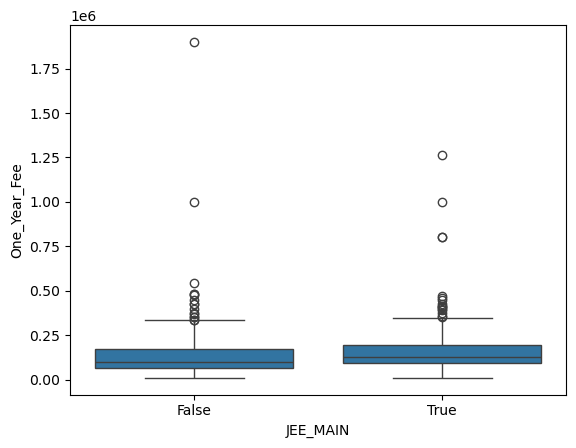

p-value: 0.0655


In [35]:
# q1

df = df_college.copy()
df['One_Year_Fee'] = pd.to_numeric(df['One_Year_Fee'].str.replace(r'[^0-9.]', '', regex=True), errors='coerce')
df['Review_Counts'] = pd.to_numeric(df['Review_Counts'].str.extract(r'(\d+)')[0], errors='coerce')
df['Rating'] = pd.to_numeric(df['Rating'], errors='coerce')

fees = df.dropna(subset=['One_Year_Fee']).copy()
fees['JEE_MAIN'] = fees['Enterance_Exam'].str.strip() == 'JEE MAIN'
print(fees.groupby('JEE_MAIN')['One_Year_Fee'].agg(['mean', 'median']).round(2))
sns.boxplot(data=fees, x='JEE_MAIN', y='One_Year_Fee')
plt.show()

from scipy.stats import ttest_ind
jee = fees.loc[fees['JEE_MAIN'], 'One_Year_Fee']
other = fees.loc[~fees['JEE_MAIN'], 'One_Year_Fee']
print('p-value:', round(ttest_ind(jee, other, equal_var=False).pvalue, 4))

**JEE MAIN colleges have higher average fees (INR 166,465 vs. INR 142,981). However, the p-value is 0.0655, so the difference is not statistically significant at 5%.**

### Create a Regression Model (4pts)

Make a model to predict the One_Year_Fee, using the variables:
<ul>
	<li>Enterance_Exam</li>
	<li>Rating</li>
	<li>Review_Counts</li>
</ul>

In [38]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Convert text columns to numbers.
for column in ['One_Year_Fee', 'Rating', 'Review_Counts']:
    df_college[column] = pd.to_numeric(
        df_college[column].astype(str).str.replace(
            r'[^0-9.]', '', regex=True
        ),
        errors='coerce'
    )
model_data = df_college.dropna(subset=[
    'One_Year_Fee', 'Enterance_Exam', 'Rating', 'Review_Counts']).copy()
features = ['Enterance_Exam', 'Rating', 'Review_Counts']
X = model_data[features]
y = model_data['One_Year_Fee']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

# Convert exam names to numeric dummy columns.
X_train_encoded = pd.get_dummies(X_train, columns=['Enterance_Exam'], dtype=int)
X_test_encoded = pd.get_dummies(X_test, columns=['Enterance_Exam'], dtype=int)
X_test_encoded = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

model = LinearRegression()
model.fit(X_train_encoded, y_train)
predictions = model.predict(X_test_encoded)
base_mae = mean_absolute_error(y_test, predictions)
base_r2 = r2_score(y_test, predictions)
print('Test MAE (INR):', round(base_mae, 2))
print('Test R-squared:', round(base_r2, 3))

Test MAE (INR): 82282.31
Test R-squared: 0.111


**The model has an average prediction error of INR 82,282 and an R-squared of 0.111. Its predictions are not very accurate.**

### Add the Place and Approved_By to the Feature Set* (2pts)

Now, add the Place and Approved_By to the feature set - these each have one column representing multiple values, which is bad. During processing, if one of those values occurs less than M times (use 10 as a value), then we will combine it with the other "other" values. This applies to the individual values in the Approved_By column, so if there are 5 colleges approved by "AICTE" and 3 colleges approved by "UGC", then we would combine those into a single "other" value.

<b>This will require some unique data processing.</b>

This is not worth a lot of points, so finish other stuff first if this is difficult. 

In [40]:
X_train_more = X_train.copy()
X_test_more = X_test.copy()
M = 10

for column in ['Place', 'Approved_By']:
    # Make one column for each city, state, or approval body.
    text = df[column].fillna('other').str.replace(r"[\[\]' ]", '', regex=True)
    extra = text.str.get_dummies(sep=',')

    # Combine values used by fewer than 10 training colleges.
    counts = extra.loc[X_train.index].sum()
    rare = counts[counts < M].index
    extra['other'] = extra[rare].any(axis=1).astype(int)
    extra = extra.drop(columns=rare).add_prefix(column + '_')
    X_train_more = X_train_more.join(extra.loc[X_train.index])
    X_test_more = X_test_more.join(extra.loc[X_test.index])

model_more = LinearRegression()
model_more.fit(X_train_more, y_train)
pred_more = model_more.predict(X_test_more)
print('MAE:', round(mean_absolute_error(y_test, pred_more), 2))
print('R-squared:', round(r2_score(y_test, pred_more), 3))

MAE: 90712.96
R-squared: -0.04


**I split Place and Approved_By into separate values and grouped rare values into other (fewer than 10 training colleges). The new model performed worse: MAE = INR 90,713 and R-squared = -0.040.** 